# Notebook 03: K-Means Clustering

**Purpose.** Apply K-Means to the numerical behavioural baseline (Representation A), choose a number of clusters using several kinds of evidence, and test whether the resulting clusters represent real structure in the data.

## A. What is K-Means?

K-Means splits users into `k` groups so that users in the same group are close to each other.

- **Centroid:** the average user of a cluster, meaning the mean of its members on every feature.
- **The algorithm:**
  1. Choose `k` starting centroids.
  2. **Assign** each user to their nearest centroid (by Euclidean distance).
  3. **Update** each centroid to the mean of its assigned users.
  4. Repeat steps 2 and 3 until assignments stop changing.
- **The role of `k`:** you must choose it in advance. The algorithm will always return exactly `k` clusters, *whether or not* the data really contains `k` groups. This fact is central to this project.
- **Why scaling matters:** distance adds up differences across features, so an unscaled feature with a large range would dominate. Notebook 02 standardized the features to prevent that.
- **Limitations:** it assumes roughly round, similar-sized clusters; it is sensitive to its starting point (which is why we use many restarts); and it can only find a local optimum.

**Configuration.** `k-means++` initialization spreads out the starting centroids. `n_init = 20` runs the algorithm 20 times and keeps the best result, because one random start can land in a poor solution. `random_state` makes results repeatable. We test `k` from 2 to 10: beyond 10, segments become too many for a person to interpret and use.

In [1]:
import sys
sys.path.append("..")

import json

import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score

from src.clustering import (
    fit_kmeans,
    name_segments,
)
from src.data_loader import ensure_output_dirs, load_clean_data, load_config, load_representation, project_path
from src.evaluation import (
    compare_to_reference,
    internal_metrics,
    make_evaluation_index,
    reference_scan,
    scan_kmeans,
    seed_stability,
    size_table,
    stability_table,
    summarise_reference,
)
from src.visualization import (
    apply_plot_style,
    plot_elbow,
    plot_metrics_vs_reference,
    plot_pca_segments,
    plot_stability,
    save_figure,
)

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)

config = load_config()
ensure_output_dirs(config)
apply_plot_style()

METRICS_DIR = project_path(config["paths"]["metrics_dir"])
PROFILES_DIR = project_path(config["paths"]["profiles_dir"])
SEED = config["random_seed"]
EVALUATION = config["evaluation"]
K_VALUES = list(range(EVALUATION["k_min"], EVALUATION["k_max"] + 1))
NUMERIC_FEATURES = config["columns"]["representation_a_numeric"]

users = load_clean_data(config)
representation_a = load_representation(config, "a")
representation_b = load_representation(config, "b")
assert (representation_a.index == users["user_id"]).all(), "Features and users must be in the same order"
assert (representation_b.index == users["user_id"]).all(), "Features and users must be in the same order"

X = representation_a.to_numpy()
X_mixed = representation_b.to_numpy()

# The same users are used to compute Silhouette for every candidate of both algorithms.
silhouette_index = make_evaluation_index(len(X), EVALUATION["silhouette_sample_size"], SEED)
print("Representation A:", X.shape, "| Representation B:", X_mixed.shape)

Representation A: (50000, 4) | Representation B: (50000, 21)


## B. Scanning the number of clusters

| Metric | What it measures | Better when | Common trap |
|---|---|---|---|
| **Inertia** (elbow) | Total squared distance from users to their centroid | Lower, but it *always* falls as `k` grows, so we look for a bend | Often there is no clear bend |
| **Silhouette** | How much closer a user is to their own cluster than to the next cluster, from -1 to 1 | Higher | Tends to favour very few clusters |
| **Davies-Bouldin** | Average similarity of each cluster to its most similar neighbour | Lower | Tends to improve as `k` rises |
| **Calinski-Harabasz** | Ratio of between-cluster to within-cluster variance | Higher | Favours compact, round clusters |

**Sampling note:** Silhouette needs pairwise distances, so it is computed on 10,000 fixed users for every candidate. Davies-Bouldin and Calinski-Harabasz use all 50,000. Notebook 05 reports Silhouette on all users for the final solutions.

In [2]:
kmeans_settings = config["kmeans"]
SELECTED_K = kmeans_settings["selected_k"]

kmeans_scan = scan_kmeans(X, K_VALUES, SEED, kmeans_settings["n_init"], kmeans_settings["max_iter"], silhouette_index)
kmeans_scan["inertia_drop_percent"] = -100 * kmeans_scan["inertia"].pct_change()
kmeans_scan.to_csv(METRICS_DIR / "kmeans_k_scan.csv", index=False)
kmeans_scan.round(4)

,k,inertia,silhouette,davies_bouldin,calinski_harabasz,smallest_cluster_share,largest_cluster_share,fit_seconds,inertia_drop_percent
0,2,164013.6696,0.1865,1.9634,10970.0890,0.4013,0.5987,1.5320,NaN
1,3,141170.8316,0.1746,1.7077,10417.4563,0.2948,0.3852,1.5728,13.9274
2,4,123080.1277,0.1761,1.4776,10415.3061,0.2266,0.2912,1.6030,12.8148
3,5,107872.5099,0.1844,1.3209,10674.5085,0.1622,0.2294,1.5578,12.3559
4,6,100814.0049,0.1745,1.4116,9837.4126,0.1500,0.1821,1.6011,6.5434
5,7,94543.8551,0.1717,1.4148,9293.9565,0.1161,0.1665,1.6253,6.2195
6,8,89040.0484,0.1711,1.3664,8899.9749,0.1117,0.1549,1.6938,5.8214
7,9,84370.0723,0.1684,1.3128,8564.1951,0.0959,0.1315,1.7427,5.2448
8,10,80341.7133,0.1701,1.2969,8272.6825,0.0841,0.1283,1.8015,4.7746


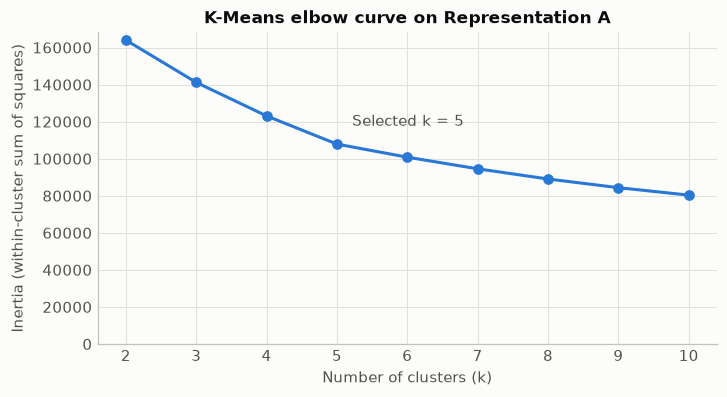

In [3]:
fig = plot_elbow(kmeans_scan, SELECTED_K, "K-Means elbow curve on Representation A")
save_figure(fig, "kmeans_elbow", config)

**Reading the scan.**

- **Inertia** falls by 12 to 14% per step up to `k = 5`, and then by only about 6.5% at `k = 6`. So there is a visible bend at `k = 5`, though the curve is fairly smooth.
- **Silhouette** is best at `k = 2` (0.1865), with `k = 5` a close second (0.1844). All values are below 0.2. A common rule of thumb treats anything below 0.25 as showing no substantial cluster structure.
- **Davies-Bouldin** has a clear local minimum at `k = 5` (1.321). Only `k = 9` and `k = 10` are slightly lower, in line with its known tendency to improve as `k` rises.
- **Calinski-Harabasz** is highest at `k = 2` (10,970), with a local peak at `k = 5` (10,675).

So the metrics favour `k = 2` or `k = 5`. They do not agree on one answer, and the separation they report is weak at every `k`.

## C. Is there real cluster structure? A reference test

Internal metrics rank candidates, but they cannot tell us whether *any* of them reflects real groups, since K-Means always returns clusters. So we ask: **would we get the same scores from data that cannot contain real groups?**

**Reference 1: column permutation.** We shuffle each feature independently. Each feature keeps exactly the same distribution, but any link between features is destroyed. A user's playlists no longer have anything to do with their listening hours. We repeat this with 10 different shuffles, using the same settings and the same users for Silhouette.

**Reference 2: a single Gaussian blob.** We generate random data from one 4-dimensional bell curve with no groups at all. This gives an intuitive baseline for the scores a structureless cloud can achieve.

**How to read it:** if the real scores are clearly better than the references, the features combine in ways that form groups. If the real scores sit on top of the references, the partitions reflect only the shape of the individual features.

This test is an addition to the original project plan. It is included because Notebook 01 found almost no correlation between features, which makes this the central question. Note that it uses no outcome variable.

real                              reference_mean                           percent_difference_from_reference                          
metric calinski_harabasz davies_bouldin silhouette calinski_harabasz davies_bouldin silhouette                 calinski_harabasz davies_bouldin silhouette
k                                                                                                                                                         
2              10970.089          1.963      0.186         10970.071          1.963      0.190                             0.000          0.007     -1.615
3              10417.456          1.708      0.175         10414.163          1.710      0.175                             0.032         -0.145     -0.221
4              10415.306          1.478      0.176         10409.414          1.473      0.176                             0.057          0.297     -0.003
5              10674.508          1.321      0.184         10667.222          1.319      0.185                             0.068          0.174     -0.453
6               9837.413          1.412      0.174          9835.924          1.400      0.175                             0.015          0.830     -0.419
7               9293.957          1.415      0.172          9296.541          1.409      0.171                            -0.028          0.433      0.110
8               8899.975          1.366      0.171          8915.661          1.374      0.170                            -0.176         -0.530      0.669
9               8564.195          1.313      0.168          8570.863          1.328      0.168                            -0.078         -1.159     -0.064
10              8272.682          1.297      0.170          8286.614          1.308      0.169                            -0.168         -0.843      0.416

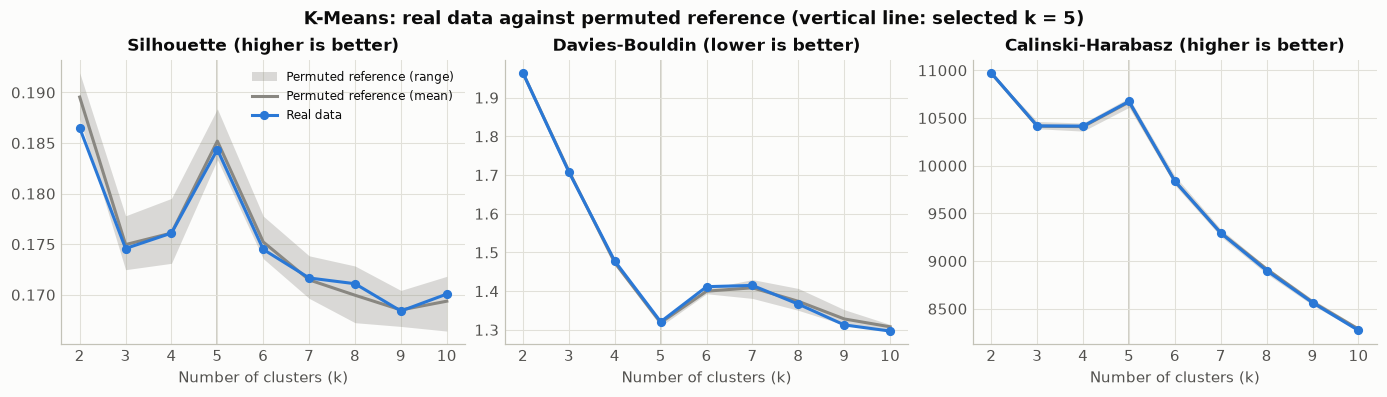

In [4]:
kmeans_reference = reference_scan(X, K_VALUES, "kmeans", EVALUATION["reference_datasets"], SEED, silhouette_index, kmeans_settings["n_init"])
kmeans_reference.to_csv(METRICS_DIR / "kmeans_reference_scan.csv", index=False)
kmeans_reference_summary = summarise_reference(kmeans_reference)

fig = plot_metrics_vs_reference(kmeans_scan, kmeans_reference_summary, SELECTED_K, "K-Means: real data against permuted reference")
save_figure(fig, "kmeans_metrics_vs_reference", config)

kmeans_vs_reference = compare_to_reference(kmeans_scan, kmeans_reference_summary)
kmeans_vs_reference.to_csv(METRICS_DIR / "kmeans_vs_reference.csv", index=False)
kmeans_vs_reference.pivot(index="k", columns="metric", values=["real", "reference_mean", "percent_difference_from_reference"]).round(3)

In [5]:
gaussian_blob = np.random.default_rng(SEED).standard_normal(X.shape)
gaussian_scan = scan_kmeans(gaussian_blob, K_VALUES, SEED, kmeans_settings["n_init"], kmeans_settings["max_iter"], silhouette_index)
gaussian_scan.to_csv(METRICS_DIR / "kmeans_gaussian_blob_scan.csv", index=False)

pd.concat(
    {
        "Real data": kmeans_scan.set_index("k")[["silhouette", "davies_bouldin", "calinski_harabasz"]],
        "Single Gaussian blob": gaussian_scan.set_index("k")[["silhouette", "davies_bouldin", "calinski_harabasz"]],
    },
    axis=1,
).round(3)

Real data                                  Single Gaussian blob                                 
   silhouette davies_bouldin calinski_harabasz           silhouette davies_bouldin calinski_harabasz
k                                                                                                   
2       0.186          1.963         10970.089                0.158          2.132          9600.312
3       0.175          1.708         10417.456                0.156          1.768          9312.819
4       0.176          1.478         10415.306                0.158          1.537          9219.476
5       0.184          1.321         10674.508                0.166          1.390          9210.253
6       0.174          1.412          9837.413                0.159          1.390          8694.326
7       0.172          1.415          9293.957                0.164          1.326          8428.910
8       0.171          1.366          8899.975                0.170          1.240          8337.923
9       0.168          1.313          8564.195                0.164          1.310          7916.358
10      0.170          1.297          8272.682                0.162          1.364          7615.906

**Result: K-Means scores on the real data are practically identical to those on data with no joint structure.**

- Across all `k` from 2 to 10, the real values differ from the permuted reference mean by at most 1.6% for Silhouette, 1.2% for Davies-Bouldin and 0.2% for Calinski-Harabasz.
- Even the "bumps" that make `k = 5` look special also appear in the permuted data.
- At `k = 5`, all three real values fall inside the reference range. Notebook 05 summarizes this across every `k`.

The single Gaussian blob, which is one cloud by construction, reaches a Silhouette of 0.166 at `k = 5` against 0.184 for the real data. That gap comes from the shapes of the individual features, such as the discrete, skewed rating, and not from how features combine, because the permuted data (same shapes, no joint structure) matches the real data.

**Conclusion:** the internal metrics give no evidence that users form natural groups in these features. The `k = 5` peak reflects the geometry of the feature distributions.

## D. Stability

A trustworthy segmentation should not change much when the algorithm is re-run. We measure agreement with the **Adjusted Rand Index (ARI)**: 1 means two partitions are identical, and 0 means no more agreement than chance.

1. **Seed stability:** runs with one random start and different seeds, on all users.
2. **Subsample stability:** models fitted on 10 independent subsamples of 5,000 users, compared on a shared set of users. We repeat this on permuted data, because stability alone does not prove structure.

In [6]:
kmeans_seed_stability = seed_stability(X, K_VALUES, EVALUATION["stability_seeds"])
kmeans_seed_stability.to_csv(METRICS_DIR / "kmeans_seed_stability.csv", index=False)
kmeans_seed_stability.round(3)

,k,mean_ari,min_ari
0,2,0.376,0.000
1,3,0.360,0.060
2,4,0.608,0.331
3,5,0.957,0.915
4,6,0.579,0.440
5,7,0.424,0.283
6,8,0.338,0.209
7,9,0.358,0.221
8,10,0.409,0.222


dataset,Permuted reference,Real data
k,,
2,0.933,0.809
3,0.570,0.447
4,0.477,0.447
5,0.765,0.801
6,0.501,0.498
7,0.383,0.384
8,0.340,0.329
9,0.364,0.362
10,0.403,0.374


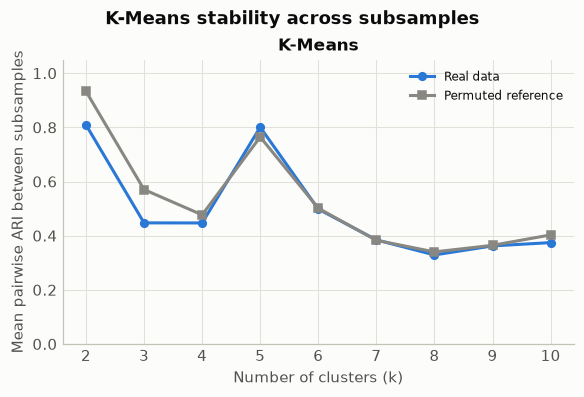

In [7]:
def kmeans_labels(X_subset, k, run):
    return fit_kmeans(X_subset, k, run, n_init=10).labels_

kmeans_stability = stability_table(
    X, kmeans_labels, "K-Means", K_VALUES, EVALUATION["stability_subsamples"], EVALUATION["stability_subsample_size"], SEED
)
kmeans_stability.to_csv(METRICS_DIR / "kmeans_subsample_stability.csv", index=False)
fig = plot_stability(kmeans_stability, "K-Means stability across subsamples")
save_figure(fig, "kmeans_stability", config)
kmeans_stability.pivot(index="k", columns="dataset", values="mean_ari").round(3)

**Result.**

- **Across random starts,** `k = 5` is by far the most repeatable (mean ARI 0.957, minimum 0.915). All other `k` reach 0.608 or less. For example, single-start runs at `k = 2` can find entirely different partitions (minimum ARI 0.000), which is exactly why we use 20 restarts.
- **Across subsamples,** `k = 5` is again strong among higher values of `k` (0.801), and `k = 2` is similar (0.809).

**A key warning:** the permuted data is also stable at those same values of `k` (0.765 at `k = 5` and 0.933 at `k = 2`). So stability here means that K-Means has a reliable way to slice this *shape* of cloud. It shows that the method is repeatable, not that the clusters are natural.

## E. Interpretability of the candidates

Numbers alone cannot choose `k`. The tables below show cluster means in **original units** for the leading candidates. A candidate is useful only if its clusters differ in understandable ways.

In [8]:
candidate_profiles = {}
for k in [2, 3, 4, 5, 6]:
    labels = fit_kmeans(X, k, SEED, kmeans_settings["n_init"], kmeans_settings["max_iter"]).labels_
    profile = users.groupby(labels)[NUMERIC_FEATURES].mean().round(2)
    profile["percent_of_users"] = (100 * np.bincount(labels) / len(labels)).round(1)
    candidate_profiles[k] = profile
    print(f"k = {k}")
    display(profile)

k = 2


,avg_listening_hours_per_week,playlists_created,avg_skips_per_day,music_suggestion_rating_1_to_5,percent_of_users
0,10.00,8.00,10.00,2.49,40.1
1,9.98,8.01,10.04,4.42,59.9


k = 3


,avg_listening_hours_per_week,playlists_created,avg_skips_per_day,music_suggestion_rating_1_to_5,percent_of_users
0,9.98,7.04,10.01,2.40,32.0
1,10.00,6.35,10.05,4.47,38.5
2,9.99,11.22,10.01,3.92,29.5


k = 4


,avg_listening_hours_per_week,playlists_created,avg_skips_per_day,music_suggestion_rating_1_to_5,percent_of_users
0,7.86,6.38,8.17,4.18,29.1
1,11.36,7.08,13.49,4.06,24.4
2,10.58,7.52,9.51,2.14,22.7
3,10.62,11.38,9.24,3.99,23.8


k = 5


,avg_listening_hours_per_week,playlists_created,avg_skips_per_day,music_suggestion_rating_1_to_5,percent_of_users
0,13.68,6.53,8.52,4.04,22.4
1,10.17,7.36,14.28,3.93,19.1
2,10.27,11.78,9.45,3.97,19.3
3,9.96,7.89,9.79,1.83,16.2
4,6.02,6.87,8.61,4.03,22.9


k = 6


,avg_listening_hours_per_week,playlists_created,avg_skips_per_day,music_suggestion_rating_1_to_5,percent_of_users
0,6.24,7.06,8.90,4.45,18.2
1,10.27,7.48,14.62,3.89,16.6
2,13.34,7.26,9.11,2.36,15.0
3,10.28,12.06,9.51,3.92,17.0
4,13.41,6.70,8.72,4.46,18.1
5,6.45,7.45,9.39,2.38,15.1


### Selecting `k`

| `k` | For | Against |
|---|---|---|
| 2 | Best Silhouette and Calinski-Harabasz | Only the rating differs (2.49 versus 4.42). Hours, playlists and skips are the same in both clusters, so it is merely "low raters versus the rest" |
| 3 | | Hours are the same in all clusters, and the metrics are weaker than at `k = 5` |
| 4 | | Unstable across seeds (0.608) and weaker on all metrics than `k = 5` |
| **5** | **Near-best Silhouette, local best Davies-Bouldin and Calinski-Harabasz, elbow bend, highest seed stability; every behavioural feature distinguishes a cluster** | **Scores no better than permuted data** |
| 6 | | Worse on all metrics than `k = 5` and less stable (0.579); splits users by combinations of hours and rating |

**Decision: `k = 5`.** It has the best balance of evidence, and it is the most informative solution that remains repeatable. **"Selected" here means the most useful description of the data, not the true number of groups.** The reference test shows that no true number of groups has been established. **Alternative:** `k = 2` would have marginally better scores, but it would reduce four features to one rating split, with little descriptive value.

## F. Final K-Means model

We fit the selected configuration on all 50,000 users, and name each cluster with a mechanical rule: the feature on which its centroid is furthest from the average user, and the direction. This keeps names tied to data rather than to our hopes. Notebook 05 examines the evidence for each name in detail.

In [9]:
final_kmeans = fit_kmeans(X, SELECTED_K, SEED, kmeans_settings["n_init"], kmeans_settings["max_iter"])
kmeans_final_labels = final_kmeans.labels_

centroids = pd.DataFrame(final_kmeans.cluster_centers_, columns=NUMERIC_FEATURES)
kmeans_names = name_segments(centroids)
kmeans_segments = pd.Series(kmeans_final_labels).map(kmeans_names).rename("kmeans_segment")

kmeans_sizes = size_table(kmeans_segments)
kmeans_sizes.to_csv(PROFILES_DIR / "kmeans_cluster_sizes.csv")
display(centroids.rename(index=kmeans_names).round(2))
display(kmeans_sizes)

,avg_listening_hours_per_week,playlists_created,avg_skips_per_day,music_suggestion_rating_1_to_5
Heavy Listeners,0.93,-0.52,-0.48,0.36
Frequent Skippers,0.05,-0.23,1.34,0.26
Playlist Builders,0.07,1.34,-0.18,0.29
Low-Rating Users,-0.01,-0.04,-0.08,-1.63
Light Listeners,-1.00,-0.40,-0.45,0.35


,users,percent
segment,,
Light Listeners,11468,22.94
Heavy Listeners,11193,22.39
Playlist Builders,9673,19.35
Frequent Skippers,9554,19.11
Low-Rating Users,8112,16.22


## G. Visualizing the clusters with PCA

PCA finds new axes that capture as much variance as possible. We use it **only to draw a picture**: clustering was done in the full 4-dimensional space. Because features are uncorrelated, PCA has no shortcut here, so we first check how much of the data two components can show.

Each panel highlights one segment over all other users in gray, because five overlapping colors in a single scatter plot would be hard to read.

Variance explained by each component: [0.253 0.25  0.25  0.247]
First two components together: 50.3%


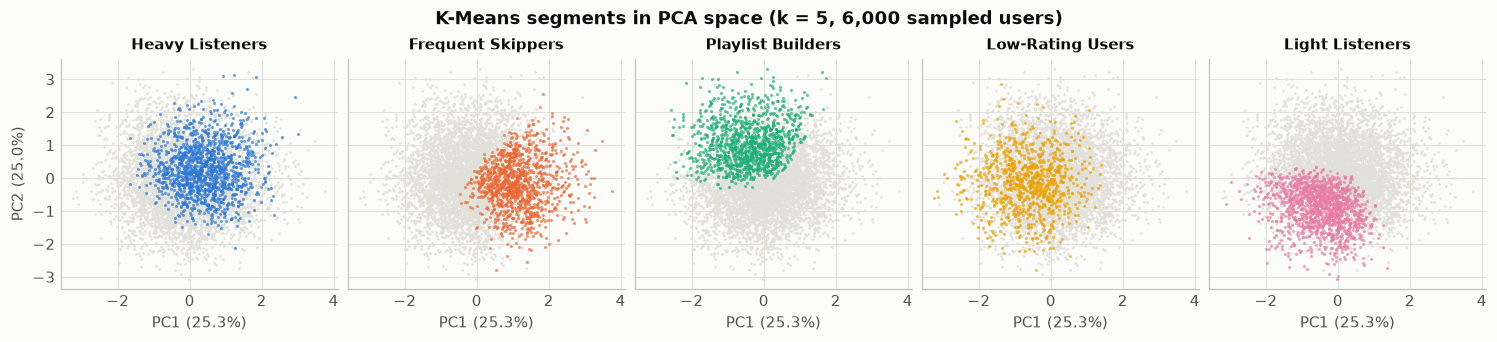

In [10]:
pca = PCA(random_state=SEED).fit(X)
print("Variance explained by each component:", pca.explained_variance_ratio_.round(3))
print(f"First two components together: {pca.explained_variance_ratio_[:2].sum():.1%}")

coordinates = pca.transform(X)[:, :2]
fig = plot_pca_segments(coordinates, kmeans_segments, pca.explained_variance_ratio_, f"K-Means segments in PCA space (k = {SELECTED_K}, 6,000 sampled users)", SEED)
save_figure(fig, "kmeans_pca_segments", config)

**Limits of this picture.** The four components explain 25.3%, 25.0%, 25.0% and 24.7% of the variance: every direction matters equally, which is what uncorrelated features produce. The plot shows only 50.3% of the variance, so half of the information is invisible. This is why Heavy Listeners and Low-Rating Users appear to overlap in the middle: what separates them lies largely in the other two components. Overlap in this picture alone cannot prove that clusters overlap.

The picture does show one continuous cloud with **no gaps between segments**, consistent with the reference test. Clusters here look like slices of a single cloud.

## H. Representation B: adding genre and device

We repeat the scan on the mixed representation. **Scores from different feature spaces are not directly comparable:** Silhouette tends to fall simply because more dimensions make all distances more similar. So the useful questions are whether the partition changes, and whether clusters separate users by genre or device.

In [11]:
mixed_scan = scan_kmeans(X_mixed, K_VALUES, SEED, kmeans_settings["n_init"], kmeans_settings["max_iter"], silhouette_index)
mixed_scan.to_csv(METRICS_DIR / "kmeans_representation_b_scan.csv", index=False)
display(mixed_scan[["k", "silhouette", "davies_bouldin", "calinski_harabasz"]].round(3))

mixed_labels = fit_kmeans(X_mixed, SELECTED_K, SEED, kmeans_settings["n_init"], kmeans_settings["max_iter"]).labels_
print(f"ARI with the Representation A partition at k = {SELECTED_K}: {adjusted_rand_score(kmeans_final_labels, mixed_labels):.3f}")

for column in config["columns"]["representation_b_categorical"]:
    shares = 100 * pd.crosstab(mixed_labels, users[column], normalize="index")
    spread = (shares.max() - shares.min()).max()
    print(f"{column}: largest difference in any category's share between clusters = {spread:.1f} percentage points")

,k,silhouette,davies_bouldin,calinski_harabasz
0,2,0.123,2.520,7201.878
1,3,0.110,2.275,6479.112
2,4,0.109,2.030,6138.141
3,5,0.110,1.869,5945.332
4,6,0.099,2.006,5314.159
5,7,0.096,2.006,4872.862
6,8,0.093,1.997,4536.785
7,9,0.087,2.006,4235.473
8,10,0.086,1.981,4001.747


ARI with the Representation A partition at k = 5: 0.963
favorite_genre: largest difference in any category's share between clusters = 1.1 percentage points
primary_device: largest difference in any category's share between clusters = 1.7 percentage points


**Result.** Adding genre and device barely changes the K-Means result: ARI of 0.963 with the Representation A partition. In the mixed solution, category shares differ by at most 1.1 percentage points for genre and 1.7 for device across clusters, so clusters do not separate users by these variables. The added columns contribute distance noise and no new grouping. As a result, **Representation A is kept as the final basis**. Silhouette is lower at `k = 5` (0.110 against 0.184), but as noted above, that comparison is not like for like.

## I. Save the results

In [12]:
kmeans_label_table = pd.DataFrame(
    {"user_id": users["user_id"], "kmeans_label": kmeans_final_labels, "kmeans_segment": kmeans_segments}
)
kmeans_label_table.to_csv(PROFILES_DIR / "kmeans_labels.csv", index=False)

selected_row = kmeans_scan.loc[kmeans_scan["k"] == SELECTED_K].iloc[0]
kmeans_record = {
    "algorithm": "KMeans",
    "representation": "A",
    "features": NUMERIC_FEATURES,
    "selected_k": SELECTED_K,
    "init": kmeans_settings["init"],
    "n_init": kmeans_settings["n_init"],
    "max_iter": kmeans_settings["max_iter"],
    "random_seed": SEED,
    "k_range": K_VALUES,
    "silhouette_sample_size": EVALUATION["silhouette_sample_size"],
    "segment_names": {str(label): name for label, name in kmeans_names.items()},
    "fit_seconds_at_selected_k": float(selected_row["fit_seconds"]),
    "inertia": float(final_kmeans.inertia_),
}
with open(METRICS_DIR / "kmeans_model_config.json", "w", encoding="utf-8") as file:
    json.dump(kmeans_record, file, indent=2)

assert len(kmeans_label_table) == len(users) and kmeans_label_table["user_id"].is_unique
print("Saved K-Means labels, sizes, metrics and configuration.")

Saved K-Means labels, sizes, metrics and configuration.


## Conclusion

- **Selected model:** K-Means with `k = 5`, 20 restarts and `k-means++`, on Representation A.
- **Segments:** Light Listeners (22.94%), Heavy Listeners (22.39%), Playlist Builders (19.35%), Frequent Skippers (19.11%) and Low-Rating Users (16.22%).
- **Quality:** Silhouette 0.184 on the fixed subset, which is weak.
- **Stability:** high for this `k` across seeds and subsamples.
- **Main caveat:** real scores and stability are matched by permuted data. These are useful and repeatable slices of a continuous population, without evidence that they are natural groups.